In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
path ='/content/hospital_readmissions_raw.csv'

In [3]:
df = pd.read_csv(path)

In [4]:
df

,Encounter_ID,Discharge_Date,Age,Gender,Primary_Diagnosis,Admission_Type,Length_of_Stay,Num_Prior_Admissions,Medication_Count,Follow_Up_Scheduled,Discharge_Destination,Readmitted_30_Days,Readmission_Cost
0,ENC-218521,2024-05-16,85.0,Male,DIABETES,Urgent,2,0.0,14.0,No,Home Health Care,0,0.00
1,ENC-139631,2024-01-31,81.0,female,Heart_Failure,Elective,6,0.0,7.0,Yes,Home,0,0.00
2,ENC-151143,01-12-2024,78.0,Male,HEART FAILURE,Urgent,6,0.0,6.0,Yes,Home Health Care,0,0.00
3,ENC-142802,2024-09-26,44.0,Female,Heart Failure,Urgent,2,1.0,7.0,Yes,Home Health Care,0,0.00
4,ENC-172942,2024/02/09,26.0,Female,heart failure,Urgent,3,1.0,11.0,Yes,Home Health Care,0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
121495,ENC-210268,04-26-2024,23.0,Female,PNEUMONIA,Urgent,2,0.0,1.0,NaN,Rehab/Skilled Nursing,0,0.00
121496,ENC-219879,2024-04-17,89.0,Female,Diabetes,Emergency,3,2.0,6.0,Yes,Home,1,20198.78
121497,ENC-203694,04-15-2024,35.0,M,Heart Failure,Emergency,2,0.0,10.0,TRUE,Home Health Care,0,0.00
121498,ENC-100860,2024-09-05,31.0,Female,diabetes,Urgent,3,0.0,13.0,No,Home,0,0.00


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121500 entries, 0 to 121499
Data columns (total 13 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Encounter_ID           121500 non-null  object 
 1   Discharge_Date         121500 non-null  object 
 2   Age                    119065 non-null  float64
 3   Gender                 117855 non-null  object 
 4   Primary_Diagnosis      121500 non-null  object 
 5   Admission_Type         115524 non-null  object 
 6   Length_of_Stay         121500 non-null  int64  
 7   Num_Prior_Admissions   117849 non-null  float64
 8   Medication_Count       121500 non-null  float64
 9   Follow_Up_Scheduled    116628 non-null  object 
 10  Discharge_Destination  115517 non-null  object 
 11  Readmitted_30_Days     121500 non-null  int64  
 12  Readmission_Cost       121500 non-null  float64
dtypes: float64(4), int64(2), object(7)
memory usage: 12.1+ MB


In [6]:
df.describe()

,Age,Length_of_Stay,Num_Prior_Admissions,Medication_Count,Readmitted_30_Days,Readmission_Cost
count,119065.000000,121500.000000,117849.000000,121500.000000,121500.000000,121500.000000
mean,54.059337,4.998831,0.757529,13.951621,0.190181,3080.972186
std,22.046002,2.626128,1.037517,69.971811,0.392446,6653.363952
min,-5.000000,1.000000,0.000000,1.000000,0.000000,0.000000
25%,36.000000,3.000000,0.000000,7.000000,0.000000,0.000000
50%,54.000000,5.000000,0.000000,9.000000,0.000000,0.000000
75%,72.000000,6.000000,1.000000,11.000000,0.000000,0.000000
max,210.000000,27.000000,4.000000,999.000000,1.000000,23999.710000




---



**A. DATA CLEANING**




1. *Standardizing Gender*




In [7]:
df.value_counts('Gender')

gender_map = { "M" : "Male",
              "Male":"Male",
               "Female":"Female",
              "F": "Female",
              "male": "Male",
               "female": "Female",
               "MALE":"Male"}

df['Gender']= df['Gender'].astype(str).str.strip().map(gender_map)



2.*Cleaning Primary_Diagnosis*

In [8]:

df.value_counts('Primary_Diagnosis')

diagnosis_map= {"PNEUMONIA":"Pneumonia",
                "pneumonia":"Pneumonia",
                "Pneumonia":"Pneumonia",
                "DIABETES":"Diabetes",
                "diabetes":"Diabetes",
                "Diabetes":"Diabetes",
                "Heart_Failure":"Heart Failure",
                "heart failure":"Heart Failure",
                "HEART FAILURE":"Heart Failure",
                "Heart Failure":"Heart Failure",
                "COPD":"COPD",
                "Copd":"COPD",
                "copd":"COPD",
                "hip/knee":"Hip/Knee Replacement",
                "Hip/Knee Replacement":"Hip/Knee Replacement",
                "HIP/KNEE":"Hip/Knee Replacement",
                "Hip/Knee":"Hip/Knee Replacement",}

df['Primary_Diagnosis'] = df['Primary_Diagnosis'].astype(str).str.strip().map(diagnosis_map)






In [9]:
df.value_counts('Primary_Diagnosis')




,count
Primary_Diagnosis,
Heart Failure,30453
Pneumonia,26496
Diabetes,24304
COPD,21925
Hip/Knee Replacement,18322


3. Cleaning Follow_Up_Scheduled

In [10]:

df.value_counts('Follow_Up_Scheduled')
follow_up_map={"Yes":"Yes",
               "TRUE":"Yes",
               "Y":"Yes",
               "N":"No",
               "No":"No",
               "FALSE":"No"}

df['Follow_Up_Scheduled']=df['Follow_Up_Scheduled'].astype(str).str.strip().map(follow_up_map)





4. Standardize Discharge_Date to Datetime


In [11]:
df['Discharge_Date']= pd.to_datetime(df['Discharge_Date'],format='mixed')

#verifed
print(df['Discharge_Date'].dtype)
print(df['Discharge_Date'].max())
print(df['Discharge_Date'].min())

datetime64[ns]
2024-12-30 00:00:00
2024-01-01 00:00:00


5. Duplicate Handling


In [12]:
df.duplicated()
df= df.drop_duplicates().copy()

6. NaN Handling


In [13]:
df.isna().sum()

,0
Encounter_ID,0
Discharge_Date,0
Age,2400
Gender,3600
Primary_Diagnosis,0
Admission_Type,5898
Length_of_Stay,0
Num_Prior_Admissions,3600
Medication_Count,0
Follow_Up_Scheduled,4800


In [14]:
df = df.dropna()



---



**B. DATA MANIPULATION**






1. Age_Gr column added

In [15]:
from numpy._core.umath import NAN
def age(x):
    if x < 40:
        return "Under 40"
    elif x <=55 and x>=40:
        return "40-55"
    elif x  >=56 and x <=70:
        return "56-70"
    else:
         return "70+"


df['Age_Gr'] = df['Age'].apply(age)

2. Discharge_Month column added

In [16]:
df['Discharge_Month'] = df['Discharge_Date'].dt.month_name()






---



**C. KPIs**

**1. Overall 30-Day Readmission Rate**



In [17]:
readmitted_count = df['Readmitted_30_Days'].value_counts().reset_index()

Readmitted_30_Days = readmitted_count.iloc[1,1]

Total_encounters = df['Encounter_ID'].count()


In [18]:
Overall_30_Day_Readmission_Rate = round((Readmitted_30_Days/ Total_encounters)*100,2)

print(f'{Overall_30_Day_Readmission_Rate}%')

#Readmitted_30_Days = df[df['Readmitted_30_Days']== 1].sum()

20.22%


**2. Total Readmission Financial Exposure**

In [19]:
Readmission_cost = df['Readmission_Cost'].sum()
print(Readmission_cost)

314544204.76


**3. Average Cost per Readmission**

In [20]:
Average_Cost_per_Readmission = round(Readmission_cost/Readmitted_30_Days,2)

print(Average_Cost_per_Readmission)


16206.1


**4. High-Risk Diagnosis Readmission Rate**

In [21]:

High_Risk= df.groupby('Primary_Diagnosis')['Readmitted_30_Days'].agg(Total='count',Readmissions='sum').reset_index()

High_Risk['Rate'] = round((High_Risk['Readmissions']/High_Risk['Total'])*100,2)

High_Risk



,Primary_Diagnosis,Total,Readmissions,Rate
0,COPD,17289,3487,20.17
1,Diabetes,19136,3807,19.89
2,Heart Failure,24063,4885,20.30
3,Hip/Knee Replacement,14523,2972,20.46
4,Pneumonia,20986,4258,20.29


**5. Post-Discharge Follow-Up Risk Gap**

In [56]:
'''count_follow_up_yes = ((df['Follow_Up_Scheduled'] == 'Yes') & (df['Readmitted_30_Days'] == 1)).sum()
count_follow_up_no =  len(df.query("Follow_Up_Scheduled == 'No' and Readmitted_30_Days == 1 " ))

print(f'No. of Readmissions given a Follow up post Discharge: {count_follow_up_yes}')
print(f'No. of Readmissions not given a Follow up post Discharge: {count_follow_up_no}')

Gap = count_follow_up_no - count_follow_up_yes

print(f'Gap: {Gap}')'''

follow_up_gap = df.groupby('Follow_Up_Scheduled')['Readmitted_30_Days'].agg(Total='count',Readmissions='sum').reset_index()
follow_up_gap['Rate'] = round((follow_up_gap['Readmissions']/follow_up_gap['Total'])*100,2)

follow_up_gap

Gap = follow_up_gap.iloc[0,3]-follow_up_gap.iloc[1,3]


print(f'Gap: {Gap}')

Gap: 34.75




---



**D. DATA VISUALIZATION**

In [57]:
sns.set_theme(style='whitegrid')
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

1. Monthly Readmission Rate(Line Chart)

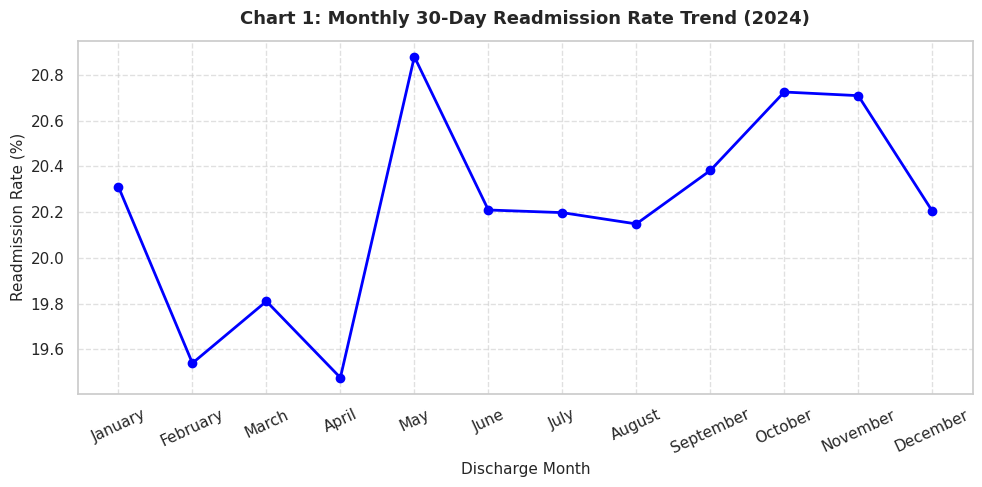

In [58]:
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

df['Discharge_Month'] = pd.Categorical(df['Discharge_Month'], categories=month_order)

monthly_trend = df.groupby('Discharge_Month',observed=False)['Readmitted_30_Days'].agg(total='count',readmitted='sum').reset_index()

monthly_trend['Rate'] = (monthly_trend['readmitted']/monthly_trend['total'])*100



monthly_trend


plt.figure(figsize=(10, 5))
plt.plot(monthly_trend['Discharge_Month'],monthly_trend["Rate"],color='blue',marker='o', linewidth=2)
plt.xticks(rotation=25)


plt.title('Chart 1: Monthly 30-Day Readmission Rate Trend (2024)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Discharge Month', fontsize=11)
plt.ylabel('Readmission Rate (%)', fontsize=11)
plt.xticks(rotation=25)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


2. Readmission Rate by Primary Diagnosis (Horizontal Bar Chart)

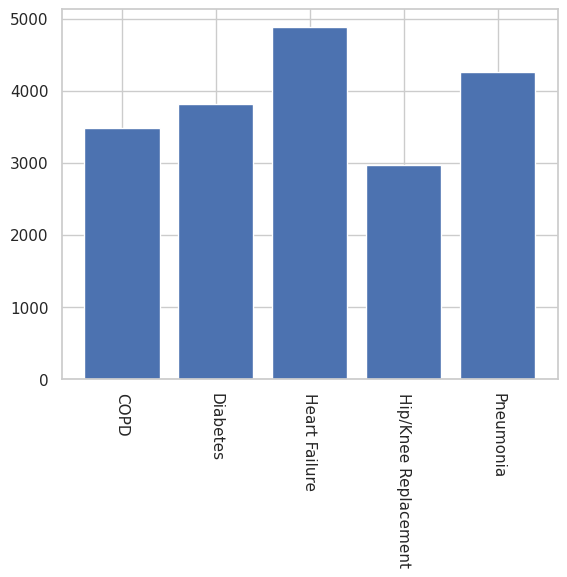

,Primary_Diagnosis,Readmissions,Total_Cost
0,COPD,3487,56559946.38
1,Diabetes,3807,61723060.41
2,Heart Failure,4885,78641325.22
3,Hip/Knee Replacement,2972,48406914.18
4,Pneumonia,4258,69212958.57


In [59]:
Readmission_Rate = df.groupby('Primary_Diagnosis').agg(Readmissions=('Readmitted_30_Days','sum'), Total_Cost=('Readmission_Cost','sum')).reset_index()
plt.bar(Readmission_Rate['Primary_Diagnosis'],Readmission_Rate['Readmissions'])
plt.xticks(rotation=270)
plt.show()

Readmission_Rate



3. Impact of Post-Discharge Follow-Up & Destination (100% Stacked Bar or Clustered Column Chart)


,Follow_Up_Scheduled,Total,Readmissions,Rate
0,No,31525,13731,43.56
1,Yes,64472,5678,8.81


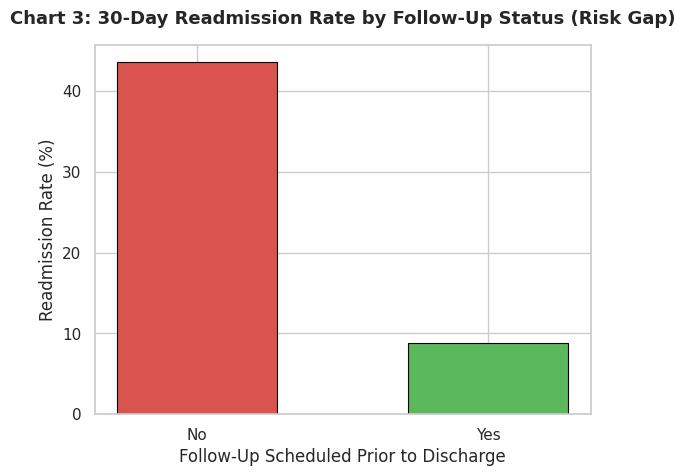

In [63]:
Follow_Up_Chart = df.groupby('Follow_Up_Scheduled')['Readmitted_30_Days'].agg(Total='count',Readmissions='sum').reset_index()

Follow_Up_Chart['Rate'] = round((Follow_Up_Chart['Readmissions']/Follow_Up_Chart['Total'])*100,2)

colors = ['#d9534f' if x == 'No' else '#5cb85c' if x == 'Yes' else '#6c757d' for x in Follow_Up_Chart['Follow_Up_Scheduled']]

plt.bar(Follow_Up_Chart['Follow_Up_Scheduled'],Follow_Up_Chart['Rate'],color=colors, width=0.55, edgecolor='black', linewidth=0.8)
plt.title('Chart 3: 30-Day Readmission Rate by Follow-Up Status (Risk Gap)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Follow-Up Scheduled Prior to Discharge', fontsize=12)
plt.ylabel('Readmission Rate (%)', fontsize=12)
Follow_Up_Chart


4. Risk Matrix: Readmission Rate by Prior Admissions & Age Bracket (Heatmap or Grouped Bar Chart)


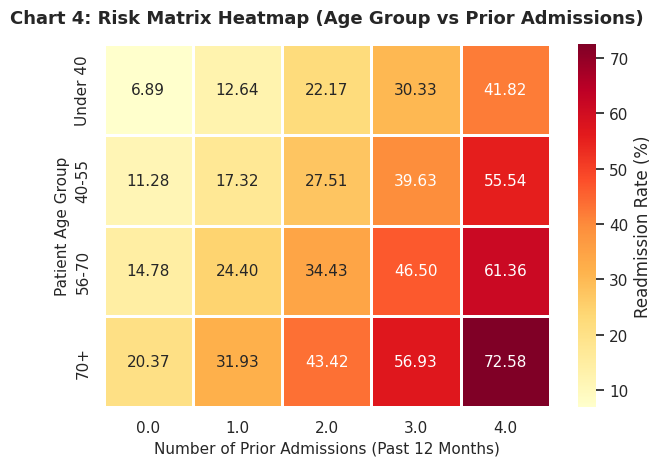

In [61]:
Risk_Matrix = df[df['Age_Gr'] != 'Unknown'].groupby(['Age_Gr','Num_Prior_Admissions'])['Readmitted_30_Days'].agg(Readmissions='sum',Total='count').reset_index()

Risk_Matrix['Rate']=round((Risk_Matrix['Readmissions']/Risk_Matrix['Total'])*100,2)

heatmap_data = Risk_Matrix.pivot_table(index='Age_Gr',columns='Num_Prior_Admissions',values='Rate')

heatmap_data = heatmap_data.reindex(['Under 40', '40-55', '56-70', '70+'])

sns.heatmap(heatmap_data,annot=True,fmt='.2f',cmap="YlOrRd",cbar_kws={'label': 'Readmission Rate (%)'},linewidths=1)


plt.title('Chart 4: Risk Matrix Heatmap (Age Group vs Prior Admissions)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Number of Prior Admissions (Past 12 Months)', fontsize=11)
plt.ylabel('Patient Age Group', fontsize=11)
plt.tight_layout()
plt.show()



5. Financial Exposure by Admission Type (Donut Chart or Treemap)


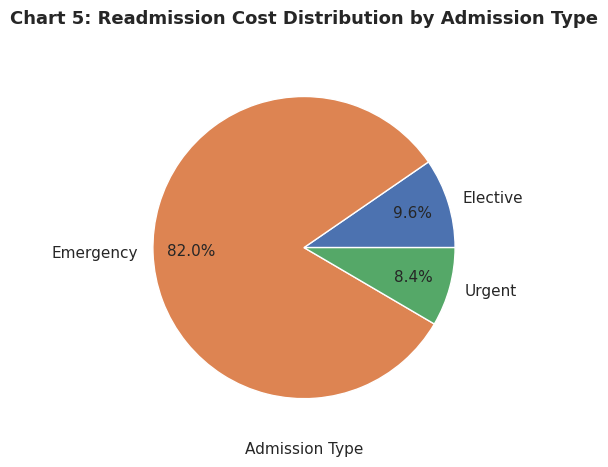

,Admission_Type,Total
0,Elective,30174948
1,Emergency,257825222
2,Urgent,26544034


In [85]:
from numpy import pad
Pie = df.groupby('Admission_Type')['Readmission_Cost'].agg(Total='sum').reset_index()

Pie['Total'] = Pie['Total'].astype(int)
plt.pie(Pie['Total'],labels=Pie['Admission_Type'],autopct='%1.1f%%',startangle=0,pctdistance=0.75)

plt.title('Chart 5: Readmission Cost Distribution by Admission Type', fontsize=13, fontweight='bold', pad=25)
plt.xlabel('Admission Type', fontsize=11)

plt.tight_layout()
plt.show()
Pie